# 实验 4　中文分词与高频词分析

## 任务要求

1. 使用 jieba 对全书分词，输出分词结果示例。
2. 准备停用词表，比较“去停用词前后”的高频词变化。
3. 统计 Top20 或 Top50 高频词，说明哪些词值得保留、哪些应进一步过滤。
4. 可选：生成词云图，但不能只给图，要配合词频表解释结果。

## 数据与工具

- 停用词表：`data/stopwords_cn.txt`（中文通用停用词表）
- 分词与过滤：`sanguo_nlp.text.cut` / `filter_words`

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: three-kingdoms-nlp-lab


In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from sanguo_nlp.corpus import read_raw
from sanguo_nlp.lexicons import load_stopwords
from sanguo_nlp.plotting import use_chinese_font
from sanguo_nlp.text import cut, filter_words

use_chinese_font()

text = read_raw()
words = cut(text)
print("分词总数:", len(words))
print("分词示例:", words[100:130])

counter = Counter(words)
top20_before = counter.most_common(20)
print("\n过滤前 Top20:")
for word, freq in top20_before:
    print(f"  {word}: {freq}")

Building prefix dict from the default dictionary ...


Dumping model to file cache /var/folders/nx/fv3sdh3x51xb4259mz3dpkwc0000gp/T/jieba.cache


Loading model cost 0.489 seconds.


Prefix dict has been built successfully.


分词总数: 399543
分词示例: ['于汉', '。', '汉朝', '自', '高祖', '斩', '白蛇', '而', '起义', '，', '一统天下', '，', '后来', '光武', '中兴', '，', '传至', '献帝', '，', '遂', '分为', '三国', '。', '推其致', '乱', '之', '由', '，', '殆', '始于']

过滤前 Top20:
  ，: 44009
  。: 24704
  ": 18195
  ：: 10407
  曰: 7698
  之: 3738
  、: 3079
  ；: 2779
  ？: 2764
  ！: 2575
  也: 2304
  吾: 1950
  与: 1731
  而: 1631
  将: 1620
  
: 1587
  了: 1414
  有: 1290
  在: 1274
  为: 1269


In [3]:
stopwords = load_stopwords()
print("停用词数量:", len(stopwords))

filtered = filter_words(words, stopwords, min_len=2)
counter_filtered = Counter(filtered)

top20_after = counter_filtered.most_common(20)
print("\n过滤后 Top20:")
for word, freq in top20_after:
    print(f"  {word}: {freq}")

停用词数量: 1706

过滤后 Top20:
  曹操: 953
  孔明: 836
  将军: 772
  却说: 656
  玄德: 585
  关公: 510
  丞相: 491
  二人: 469
  荆州: 425
  玄德曰: 390
  孔明曰: 390
  张飞: 358
  商议: 344
  主公: 331
  军士: 317
  吕布: 300
  军马: 293
  赵云: 278
  刘备: 277
  引兵: 276


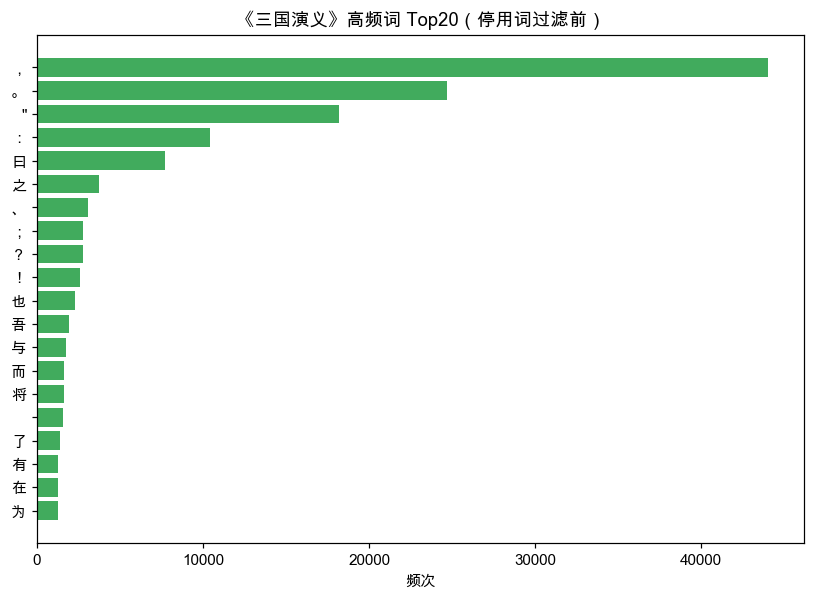

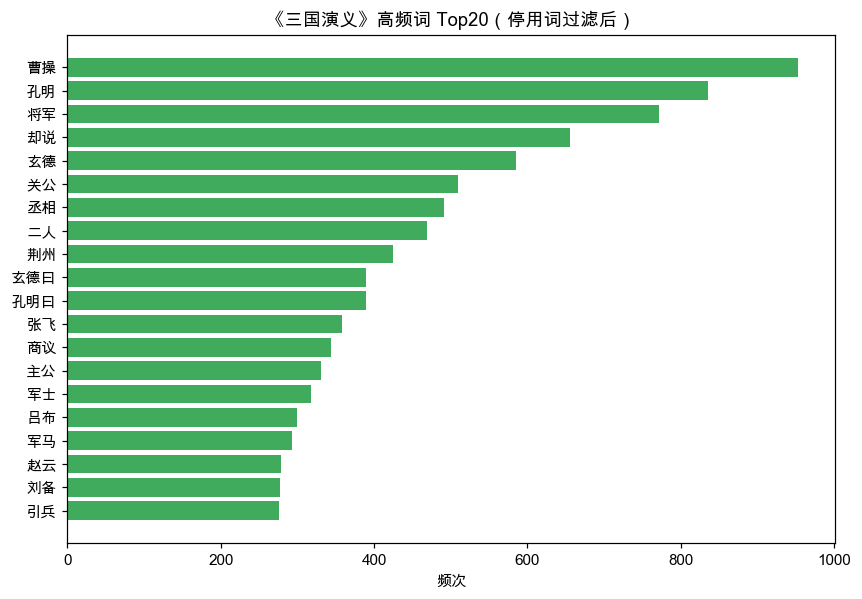

In [4]:
def plot_top_words(data, title, filename):
    labels, values = zip(*data)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(labels, values, color="#41ab5d")
    ax.invert_yaxis()
    ax.set_xlabel("频次")
    ax.set_title(title)
    fig.savefig(FIGURES_DIR / filename)
    plt.show()


plot_top_words(top20_before, "《三国演义》高频词 Top20（停用词过滤前）", "word_frequency_before.png")
plot_top_words(top20_after, "《三国演义》高频词 Top20（停用词过滤后）", "word_frequency_after.png")

词云字体: Arial Unicode.ttf


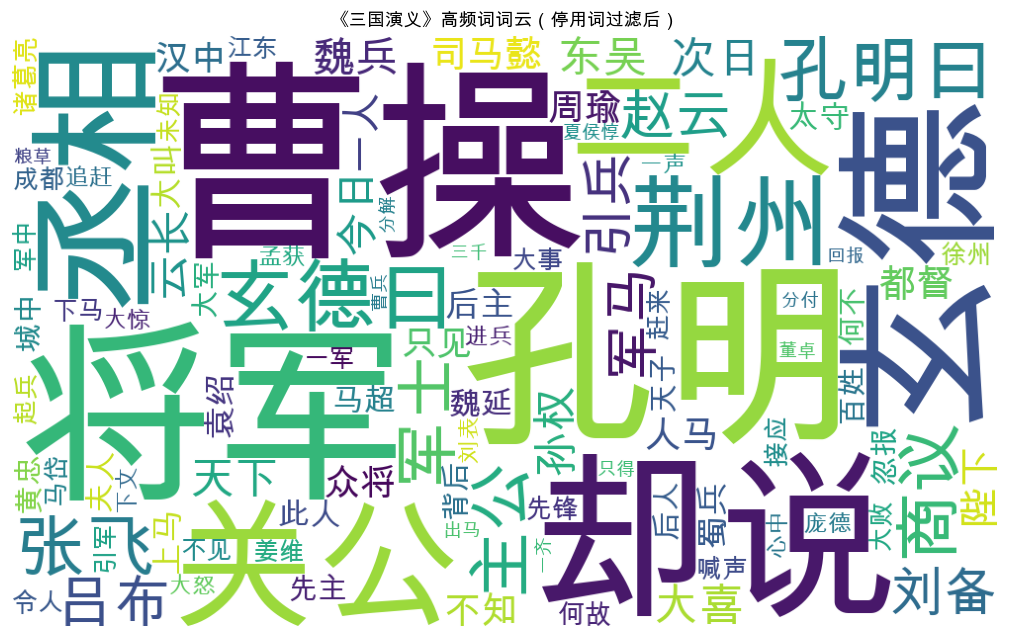

In [5]:
pd.DataFrame(top20_after, columns=["词", "频次"]).to_csv(
    TABLES_DIR / "high_freq_words.csv", index=False, encoding="utf-8-sig"
)

from matplotlib import font_manager
from wordcloud import WordCloud

family = plt.rcParams["font.sans-serif"][0]
font_path = font_manager.findfont(font_manager.FontProperties(family=family))
print("词云字体:", Path(font_path).name)

try:
    cloud = WordCloud(
        font_path=font_path, width=1000, height=600, background_color="white", max_words=100
    )
    cloud.generate_from_frequencies(dict(counter_filtered.most_common(200)))
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(cloud)
    ax.axis("off")
    ax.set_title("《三国演义》高频词词云（停用词过滤后）")
    fig.savefig(FIGURES_DIR / "wordcloud.png")
    plt.show()
except Exception as error:
    print("词云生成失败（可选步骤）：", error)

## 结果解释与实验记录

- 过滤前的高频词以“曰、之、也、不”等虚词和标点为主，对主题解释几乎没有价值。
- 只做停用词过滤仍会残留大量单字；再加上 `len(word) > 1` 与“过滤纯标点/数字”后，高频词才开始有意义。
- 过滤后的词表里仍有人名、地名（如“玄德”“曹操”“荆州”），它们对人物分析有用，但不适合作为主题词，**应在后续主题实验的词典中单独处理**，而不是简单全部删除。
- 中文没有空格分隔词语，因此需要分词；停用词表并非固定不变，应针对《三国演义》做定制。

**实验记录**

- 遇到的问题：第一次过滤后高频词表仍然全是句号、“曰”等无意义表达；解决办法是先加长度过滤，再把标点符号补充进停用词表。
- AI 工具使用记录：向 AI 询问 Windows/macOS 通用停用词表来源与清洗写法，并通过人工抽样核对高频词是否合理。